# 1 · Exploring the Gonzo tracer data

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/albgirelli/Gonzo_viewer/blob/main/notebooks/01_explore_data.ipynb)

A tracer (gadobutrol, 0.25 mmol) was injected into the spinal CSF of a healthy volunteer.
MRI was acquired before injection and about 4, 24, 48 and 70 h after. This notebook shows
what is in the tables and volumes. Everything here takes seconds to run.

In [1]:
# Setup: works both locally (inside the cloned repository) and on Google Colab.
from pathlib import Path
import subprocess

REPO_URL = "https://github.com/albgirelli/Gonzo_viewer"
if Path("../data/regions.csv").exists():
    DATA = Path("../data")
else:
    if not Path("Gonzo_viewer").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL], check=True)
    DATA = Path("Gonzo_viewer/data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Sessions and blood samples

In [2]:
sessions = pd.read_csv(DATA / "sessions.csv")
blood = pd.read_csv(DATA / "blood_plasma.csv")
sessions

,session,label,hours_after_injection,scan_time_hours
0,ses-01,Baseline,0.00,-2.53
1,ses-02,4 h,4.37,4.37
2,ses-03,24 h,23.89,23.89
3,ses-04,48 h,47.86,47.86
4,ses-05,70 h,69.90,69.90


## Regions
One row per region: FreeSurfer brain regions, CSF next to each region, and some **summary regions** (whole brain, all CSF, lobes, …). `conc_ses-XX` is the mean concentration (mmol/L) and `amount_umol_ses-XX` the amount of tracer (µmol) in the region.

In [3]:
regions = pd.read_csv(DATA / "regions.csv")
summary = regions[regions.kind == "aggregate"].set_index("name")
summary.filter(regex="volume|conc_").round(3)

,volume_ml,conc_ses-01,conc_ses-02,conc_ses-03,conc_ses-04,conc_ses-05
name,,,,,,
All brain tissue,985.619,0,0.012,0.045,0.041,0.027
Cerebral cortex,397.682,0,0.016,0.055,0.043,0.026
Cortex: frontal,135.362,0,0.012,0.055,0.047,0.029
Cortex: parietal,96.844,0,0.007,0.049,0.046,0.028
Cortex: temporal,90.512,0,0.014,0.049,0.039,0.024
Cortex: occipital,45.157,0,0.019,0.054,0.037,0.021
Cortex: cingulate,19.776,0,0.064,0.090,0.040,0.020
Cortex: insula,10.032,0,0.044,0.080,0.043,0.022
Cerebral white matter,415.665,0,0.000,0.034,0.042,0.031


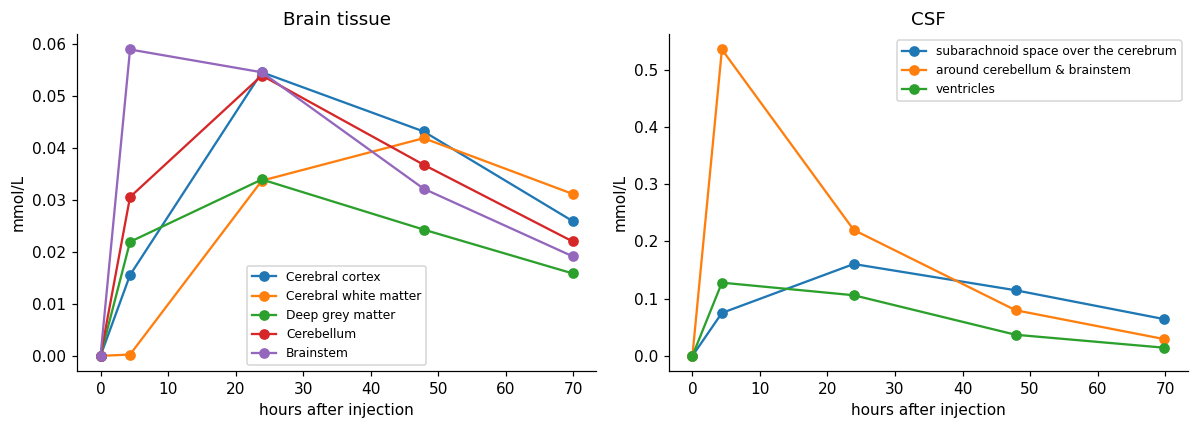

In [4]:
hours = sessions.hours_after_injection.values
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name in ["Cerebral cortex", "Cerebral white matter", "Deep grey matter", "Cerebellum", "Brainstem"]:
    ax[0].plot(hours, summary.loc[name].filter(like="conc_").values, "o-", label=name)
for name in ["CSF: subarachnoid space over the cerebrum", "CSF: around cerebellum & brainstem", "CSF: ventricles"]:
    ax[1].plot(hours, summary.loc[name].filter(like="conc_").values, "o-", label=name.replace("CSF: ", ""))
ax[0].set_title("Brain tissue"); ax[1].set_title("CSF")
for a in ax:
    a.set_xlabel("hours after injection"); a.set_ylabel("mmol/L"); a.legend(fontsize=8)
plt.tight_layout()

## Where is the tracer? A mass balance
0.25 mmol = 250 µmol was injected. How much of it is inside the skull at each time?

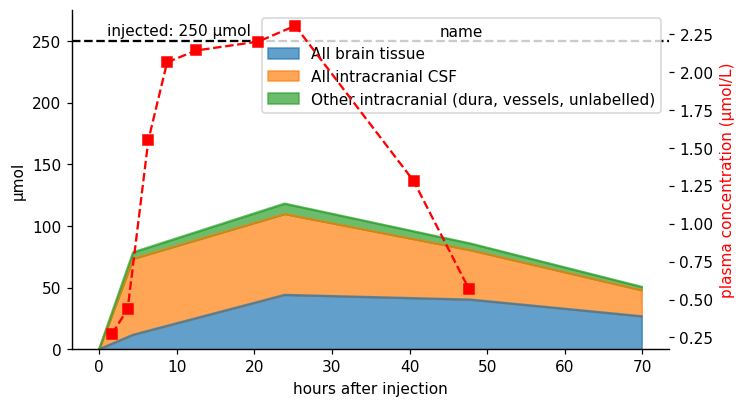

In [5]:
parts = ["All brain tissue", "All intracranial CSF", "Other intracranial (dura, vessels, unlabelled)"]
amounts = summary.loc[parts].filter(like="amount_umol").T
amounts.index = hours
ax = amounts.plot.area(figsize=(7, 4), alpha=0.7)
ax.axhline(250, ls="--", c="k"); ax.text(1, 255, "injected: 250 µmol"); ax.set_ylim(0, 275)
ax.set_xlabel("hours after injection"); ax.set_ylabel("µmol")
ax2 = ax.twinx()
ax2.plot(blood.hours_after_injection, blood.plasma_concentration_mmol_per_L * 1000, "rs--", label="blood plasma")
ax2.set_ylabel("plasma concentration (µmol/L)", color="r");

## How deep does it go?
Mean concentration against distance from the brain surface (negative: CSF outside the brain; positive: inside tissue).

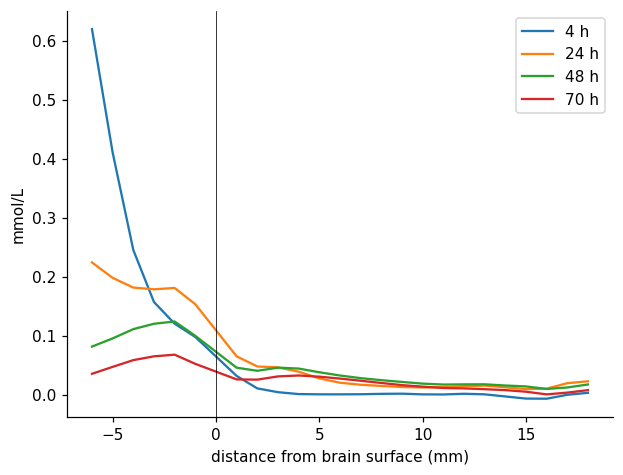

In [6]:
depth = pd.read_csv(DATA / "depth_profiles.csv")
for h, g in depth[depth.hours_after_injection > 0].groupby("hours_after_injection"):
    plt.plot(g.depth_mm, g.mean_concentration_mmol_per_L, label=f"{h:.0f} h")
plt.axvline(0, c="k", lw=0.5); plt.xlabel("distance from brain surface (mm)"); plt.ylabel("mmol/L"); plt.legend();

## 3D volumes
`volumes/gonzo_2mm.npz` (and a 1 mm version) contains the concentration at every time (NaN outside the head), FreeSurfer labels, a T1-weighted anatomical image and DTI mean diffusivity. The `affine` maps voxel indices to scanner coordinates in mm. Axes are (right, anterior, superior).

{'concentration': (5, 70, 82, 99), 'labels': (70, 82, 99), 't1w': (70, 82, 99), 'mean_diffusivity': (70, 82, 99), 'affine': (4, 4), 'hours': (5,), 'sessions': (5,)}


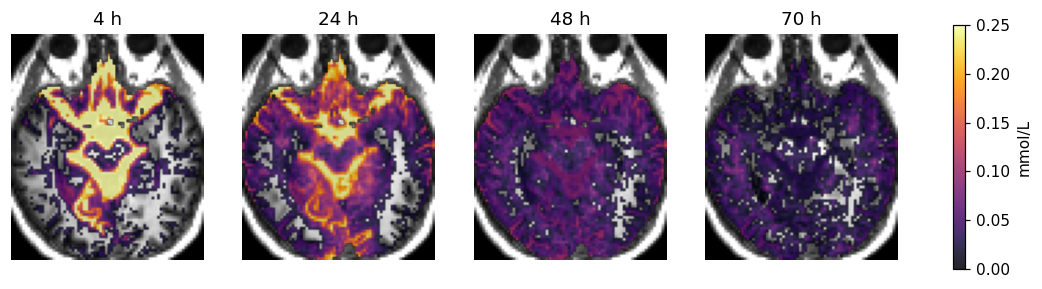

In [7]:
vol = np.load(DATA / "volumes/gonzo_2mm.npz")
print({k: vol[k].shape for k in vol.files})
c = vol["concentration"].astype(float)
z = c.shape[3] // 2 + 5
fig, ax = plt.subplots(1, 4, figsize=(13, 3.6))
for k, a in enumerate(ax):
    a.imshow(vol["t1w"][:, :, z].T, cmap="gray", origin="lower")
    im = a.imshow(np.ma.masked_less(c[k + 1, :, :, z].T, 0.01), cmap="inferno", vmin=0, vmax=0.25, origin="lower", alpha=0.85)
    a.set_title(f"{hours[k + 1]:.0f} h"); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.8, label="mmol/L");

## Where next?
* Fit a simple model to the regional curves: see `02_compartment_model.ipynb`.
* Is diffusion enough to explain the depth profiles? See `03_diffusion_depth.ipynb`.
* Simulate on the 3D brain mesh: see `04_mesh_simulation.ipynb`.
* Or do something else entirely: clustering of regional curves, a statistical model of the peak time, …